# 03 - PD Model & Scorecard Scaling
Logistic regression on WoE features. Selection: IV filter -> collinearity filter (|r| < 0.75 on WoE) -> backward elimination until every coefficient is **negative** (higher WoE = safer) and p < 0.05.

Scaling: `Score = Offset + Factor * ln(odds_good)`, **600 points at 50:1 odds, PDO = 20**, clipped to 300-850.

In [1]:
import os, sys; os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None; sys.path.insert(0,'.')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
%matplotlib inline
import statsmodels.api as sm
from src.scorecard import Scorecard
from src.metrics import gini, auc, ks
train, test = joblib.load('data/processed/split.joblib'); B = joblib.load('data/processed/binning.joblib'); binners, iv = B['binners'], B['iv']
y = train.default.values
cand = iv[iv.decision.isin(['keep', 'review: IV>0.5'])].variable.tolist()
X = pd.DataFrame({v: binners[v].transform(train[v].values) for v in cand})
kept = []
for v in cand:
    if all(abs(np.corrcoef(X[v], X[k])[0,1]) < 0.75 for k in kept): kept.append(v)
print('after IV + collinearity filter:', kept)
def fit(vs): return sm.Logit(y, sm.add_constant(X[vs])).fit(disp=0)
def select(vs):
    vs = vs[:]
    while True:
        m = fit(vs); bad = [v for v in vs if m.params[v] >= 0 or m.pvalues[v] > 0.05]
        if not bad: return vs, m
        vs.remove(max(bad, key=lambda v: m.pvalues[v]))
vs, m = select(kept); print('final variables:', vs); display(pd.DataFrame({'coef': m.params, 'p-value': m.pvalues}).round(4))

after IV + collinearity filter: ['PAY_1', 'n_delq', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'PAY_AMT1', 'PAY_AMT2', 'pay_to_bill', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT6', 'util', 'PAY_AMT5', 'bill_trend', 'EDUCATION']


final variables: ['PAY_1', 'n_delq', 'PAY_3', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT6', 'util', 'bill_trend']


,coef,p-value
const,-1.2569,0.0000
PAY_1,-0.6324,0.0000
n_delq,-0.2479,0.0000
PAY_3,-0.0923,0.0314
PAY_5,-0.1145,0.0167
PAY_6,-0.1440,0.0030
LIMIT_BAL,-0.1811,0.0005
PAY_AMT1,-0.1667,0.0030
PAY_AMT2,-0.2439,0.0001
PAY_AMT3,-0.3247,0.0000


In [2]:
sc = Scorecard(binners, {v: m.params[v] for v in vs}, m.params['const'])
print('Factor %.3f  Offset %.3f' % (sc.factor, sc.offset))
s_tr, s_te = sc.score(train), sc.score(test)
rows = []
for n, d, s in [('train', train, s_tr), ('test', test, s_te)]:
    rows.append((n, auc(d.default, -s), gini(d.default, -s), ks(d.default, -s)))
met = pd.DataFrame(rows, columns=['sample', 'AUC', 'Gini', 'KS']).set_index('sample'); display(met.round(4))
print('scorecard PD vs logistic PD max abs diff: %.2e' % np.abs(sc.pd_from_score(s_tr) - m.predict(sm.add_constant(X[vs]))).max(), '(non-zero only where scores were clipped to 300-850)')

Factor 28.854  Offset 487.123


,AUC,Gini,KS
sample,,,
train,0.7746,0.5492,0.4151
test,0.7615,0.5229,0.3964


scorecard PD vs logistic PD max abs diff: 1.28e-15 (non-zero only where scores were clipped to 300-850)


## Calibration by score band (test) and score distribution

,accounts,mean_score,predicted_PD,observed_bad
band,,,,
"(431.51300000000003, 481.036]",900,462.245,0.695,0.667
"(481.036, 506.183]",900,495.534,0.429,0.438
"(506.183, 527.936]",900,517.952,0.258,0.231
"(527.936, 535.196]",900,531.971,0.175,0.211
"(535.196, 539.8]",900,537.656,0.148,0.164
"(539.8, 543.777]",901,541.821,0.131,0.143
"(543.777, 548.085]",899,545.828,0.116,0.128
"(548.085, 552.627]",900,550.296,0.101,0.080
"(552.627, 558.603]",900,555.447,0.086,0.090


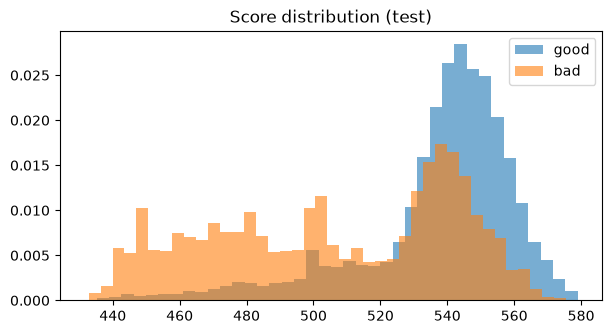

In [3]:
t = test.assign(score=s_te, pd_hat=sc.pd_from_score(s_te)); t['band'] = pd.qcut(t.score, 10, duplicates='drop')
cal = t.groupby('band').agg(accounts=('default','size'), mean_score=('score','mean'), predicted_PD=('pd_hat','mean'), observed_bad=('default','mean')); display(cal.round(3))
plt.figure(figsize=(7,3.5)); plt.hist(t[t.default==0].score, 40, alpha=.6, label='good', density=True); plt.hist(t[t.default==1].score, 40, alpha=.6, label='bad', density=True); plt.legend(); plt.title('Score distribution (test)'); plt.show()

## Sensitivity: strictly applying the 'IV > 0.5 = drop' rule
PAY_1 (latest repayment status, IV about 0.86) trips the leakage screen. It is the most recent delinquency state *before* the outcome month and is **not** derived from the target, so it is retained after review. The cost of dropping it is shown below.

In [4]:
strict = [v for v in vs if iv.set_index('variable').loc[v, 'IV'] <= 0.5]
vs2, m2 = select([v for v in kept if v in strict] + [v for v in cand if v in strict and v not in kept][:0]) if strict else ([], None)
sc2 = Scorecard(binners, {v: m2.params[v] for v in vs2}, m2.params['const']); s2 = sc2.score(test)
print('strict-rule variables:', vs2); print('Test Gini  with review-retained vars: %.4f | strict IV<=0.5 rule: %.4f' % (gini(test.default, -s_te), gini(test.default, -s2)))
sc.table.groupby('variable').points.agg(['min','max']).round(1).T

strict-rule variables: ['PAY_3', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'util', 'bill_trend']
Test Gini  with review-retained vars: 0.5229 | strict IV<=0.5 rule: 0.4540


variable,LIMIT_BAL,PAY_1,PAY_3,PAY_5,PAY_6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT6,bill_trend,n_delq,util
min,36.5,2.0,36.6,35.3,34.6,37.0,36.3,35.4,37.4,38.4,37.9,28.3,32.2
max,44.3,52.6,41.2,41.2,41.3,44.9,48.7,46.4,44.7,44.3,41.6,45.9,43.9


In [5]:
joblib.dump(dict(scorecard=sc, model_vars=vs, logit_params=m.params.to_dict()), 'data/processed/scorecard.joblib'); display(sc.table.head(12))

,variable,bin,woe,points
0,LIMIT_BAL,"(-inf, 30000]",-0.7227,36.5
1,LIMIT_BAL,"(30000, 70000]",-0.2834,38.8
2,LIMIT_BAL,"(70000, 100000]",-0.1094,39.7
3,LIMIT_BAL,"(100000, 140000]",-0.0785,39.9
4,LIMIT_BAL,"(140000, 160000]",0.2249,41.4
5,LIMIT_BAL,"(160000, 240000]",0.3083,41.9
6,LIMIT_BAL,"(240000, 360000]",0.5405,43.1
7,LIMIT_BAL,"(360000, inf]",0.7742,44.3
8,PAY_1,"(-inf, -2]",0.6742,52.6
9,PAY_1,"(-2, 0]",0.5691,50.6
